<a href="https://colab.research.google.com/github/mldyharinn/Visi-Komputer/blob/main/JS06_DL_Miladiyah_Arinal_Haq_43325213.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# === Persiapan 1: instalasi pustaka ===
%pip install -q transformers

In [2]:
# === Persiapan 2: impor, cek GPU, seed, konfigurasi ===
import os, time, random, json, zipfile, urllib.request, gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torchvision
import torchvision.transforms.functional as TF

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    N_TEST   = 20 if CEPAT else 50,
    N_TRAIN  = 60 if CEPAT else 120,
    EPOCHS   = 1 if CEPAT else 6,
    MIN_SIZE = 320 if CEPAT else 512,
    MAX_SIZE = 544 if CEPAT else 853,
    N_SAM    = 6 if CEPAT else 20,
    N_PROYEK = 8 if CEPAT else 30,
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)

FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'N_TEST': 50, 'N_TRAIN': 120, 'EPOCHS': 6, 'MIN_SIZE': 512, 'MAX_SIZE': 853, 'N_SAM': 20, 'N_PROYEK': 30}


In [3]:
# === D1.1 Unduh dan ekstrak Penn-Fudan ===
t0 = time.time()
os.makedirs("data", exist_ok=True)
if not os.path.isdir("data/PennFudanPed"):
    urllib.request.urlretrieve(
        "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip",
        "data/PennFudanPed.zip")
    with zipfile.ZipFile("data/PennFudanPed.zip") as z:
        z.extractall("data")

PF = "data/PennFudanPed"
PNGImages = "PNGImages"
PedMasks  = "PedMasks"
NAMA = sorted(os.listdir(f"{PF}/{PNGImages}"))
print("Jumlah citra:", len(NAMA), "| waktu %.1f s" % (time.time() - t0))

Jumlah citra: 170 | waktu 6.5 s


In [4]:
# === D1.2 Dataset instans: boxes, labels, masks per orang ===
class PennFudan(torch.utils.data.Dataset):
    def __init__(self, nama, augment=False):
        self.nama, self.augment = nama, augment
    def __len__(self):
        return len(self.nama)
    def muat(self, i):
        n = self.nama[i]
        img = Image.open(f"{PF}/{PNGImages}/{n}").convert("RGB")
        m = np.array(Image.open(f"{PF}/{PedMasks}/{n[:-4]}_mask.png"))
        ids = np.unique(m); ids = ids[ids != 0]
        masks = (m[None] == ids[:, None, None])  # (N,H,W) bool
        return img, masks
    def __getitem__(self, i):
        img, masks = self.muat(i)
        x = TF.to_tensor(img)
        masks = torch.from_numpy(masks).to(torch.uint8)
        if self.augment and random.random() < 0.5:
            x, masks = x.flip(-1), masks.flip(-1)
        boxes = []
        for mk in masks:
            ys, xs = torch.where(mk > 0)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32),
                  "labels": torch.ones(len(masks), dtype=torch.int64),
                  "masks": masks}
        return x, target

In [5]:
# === D1.2 Dataset instans: boxes, labels, masks per orang ===
class PennFudan(torch.utils.data.Dataset):
    def __init__(self, nama, augment=False):
        self.nama, self.augment = nama, augment
    def __len__(self):
        return len(self.nama)
    def muat(self, i):
        n = self.nama[i]
        img = Image.open(f"{PF}/{PNGImages}/{n}").convert("RGB")
        m = np.array(Image.open(f"{PF}/{PedMasks}/{n[:-4]}_mask.png"))
        ids = np.unique(m); ids = ids[ids != 0]
        masks = (m[None] == ids[:, None, None])  # (N,H,W) bool
        return img, masks
    def __getitem__(self, i):
        img, masks = self.muat(i)
        x = TF.to_tensor(img)
        masks = torch.from_numpy(masks).to(torch.uint8)
        if self.augment and random.random() < 0.5:
            x, masks = x.flip(-1), masks.flip(-1)
        boxes = []
        for mk in masks:
            ys, xs = torch.where(mk > 0)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32),
                  "labels": torch.ones(len(masks), dtype=torch.int64),
                  "masks": masks}
        return x, target

Total pejalan kaki berlabel: 423 | rata-rata per citra: 2.49 | maks: 8
x: (3, 344, 374) | boxes: (1, 4) | masks: (1, 344, 374)


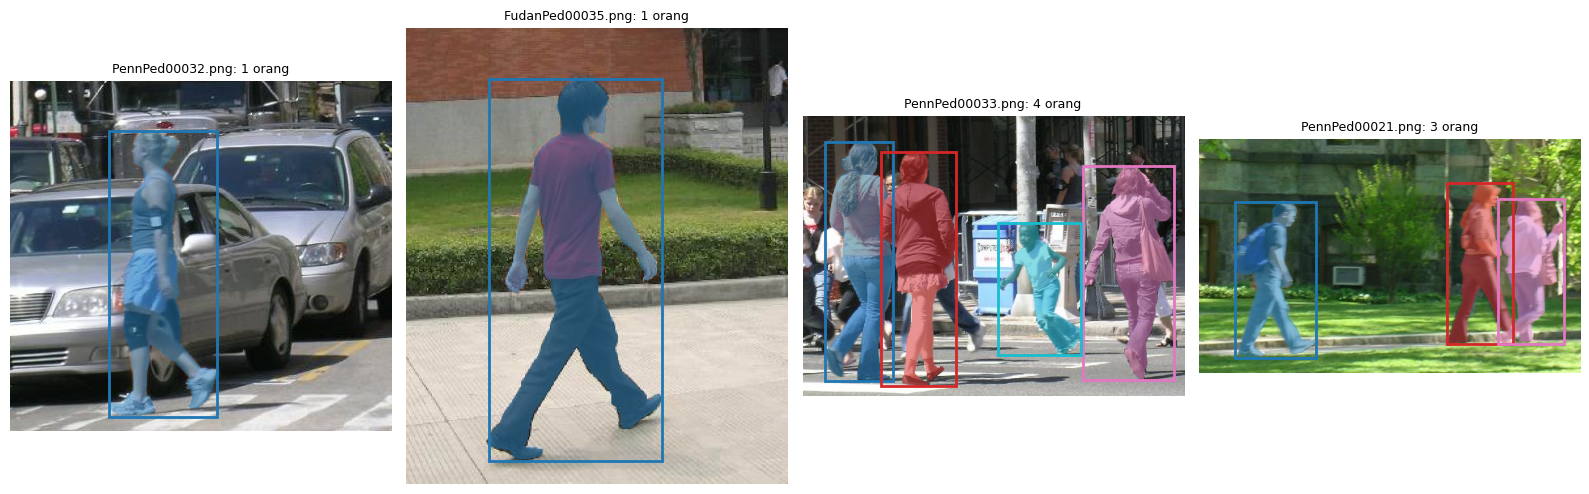

In [7]:
# === D1.3 Split data & visualisasi masker instans ===
rng = random.Random(0); acak = NAMA[:]; rng.shuffle(acak)
NAMA_TEST  = acak[:CFG["N_TEST"]]
NAMA_TRAIN = acak[50:50 + CFG["N_TRAIN"]]

ds_all = PennFudan(NAMA)
jml = [len(ds_all.muat(i)[1]) for i in range(len(NAMA))]
print("Total pejalan kaki berlabel:", sum(jml),
      "| rata-rata per citra: %.2f | maks: %d" % (np.mean(jml), max(jml)))

ds_train = PennFudan(NAMA_TRAIN, augment=True)
ds_test  = PennFudan(NAMA_TEST)

x, t = ds_test[0]
print("x:", tuple(x.shape), "| boxes:", tuple(t["boxes"].shape),
      "| masks:", tuple(t["masks"].shape))

# Memotong channel alpha agar hanya menyisakan RGB (3 channel)
WARNA = plt.cm.tab10(np.arange(10))[:: 3, :3]
def overlay(img, masks, boxes=None, alpha=0.5, judul=None, ax=None):
    arr = np.array(img).astype(float) / 255
    for k, mk in enumerate(masks):
        mk = np.asarray(mk).astype(bool)
        arr[mk] = (1 - alpha) * arr[mk] + alpha * WARNA[k % 4]
    ax.imshow(arr)
    if boxes is not None:
        for k, b in enumerate(boxes):
            b = [float(v) for v in b]
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       fill=False, color=WARNA[k % 4], lw=2))
    if judul: ax.set_title(judul, fontsize=9)
    ax.axis("off")

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for j in range(4):
    img, masks = ds_test.muat(j); _, t = ds_test[j]
    overlay(img, masks, t["boxes"], judul=f"{NAMA_TEST[j]}: {len(masks)} orang", ax=ax[j])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d1_contoh_instans.png", dpi=110)
plt.show()

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 160MB/s]


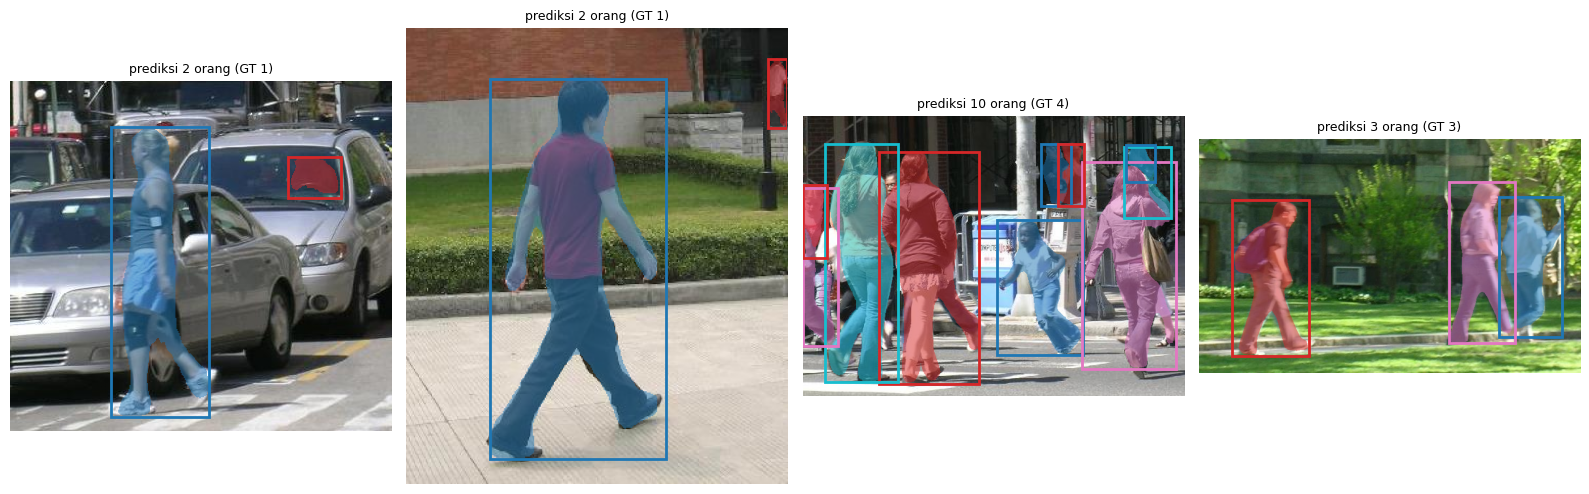

Waktu inferensi 4 citra: 4.9 s


In [8]:
# === D2.1 Muat Mask R-CNN pra-latih dan inferensi ===
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mrcnn_coco = maskrcnn_resnet50_fpn(weights=W,
    min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"]).to(DEVICE).eval()
KATEGORI = W.meta["categories"]

@torch.no_grad()
def deteksi(model, x, label_orang=1, skor_min=0.5):
    out = model([x.to(DEVICE)])[0]
    keep = (out["labels"] == label_orang) & (out["scores"] >= skor_min)
    return {k: v[keep].cpu() for k, v in out.items()}

t0 = time.time()
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for j in range(4):
    x, t = ds_test[j]; img, _ = ds_test.muat(j)
    o = deteksi(mrcnn_coco, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"],
            judul=f"prediksi {len(o['scores'])} orang (GT {len(t['labels'])})", ax=ax[j])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d2_maskrcnn_coco.png", dpi=110)
plt.show()
print("Waktu inferensi 4 citra: %.1f s" % (time.time() - t0))

In [9]:
# === D3.1 Siapkan model 2 kelas (latar + pejalan kaki) ===
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

set_seed(42)
mrcnn_ft = maskrcnn_resnet50_fpn(weights=W,
    min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"])
in_feat = mrcnn_ft.roi_heads.box_predictor.cls_score.in_features
mrcnn_ft.roi_heads.box_predictor  = FastRCNNPredictor(in_feat, 2)
mrcnn_ft.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, 2)

for p in mrcnn_ft.backbone.body.parameters():
    p.requires_grad = False  # bekukan ResNet-50

mrcnn_ft = mrcnn_ft.to(DEVICE)
dilatih = [p for p in mrcnn_ft.parameters() if p.requires_grad]
print("Parameter dilatih: %.2f juta dari %.2f juta" % (
    sum(p.numel() for p in dilatih) / 1e6,
    sum(p.numel() for p in mrcnn_ft.parameters()) / 1e6))

Parameter dilatih: 20.47 juta dari 43.92 juta


In [10]:
# === D3.2 Loop pelatihan ===
collate  = lambda b: tuple(zip(*b))
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=2,
                                       shuffle=True, collate_fn=collate)
opt = torch.optim.SGD(dilatih, lr=0.005, momentum=0.9, weight_decay=5e-4)

riwayat = []; t0 = time.time()
for ep in range(CFG["EPOCHS"]):
    mrcnn_ft.train()
    for it, (xs, ts) in enumerate(dl_train):
        xs = [x.to(DEVICE) for x in xs]
        ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in ts]
        losses = mrcnn_ft(xs, ts)
        loss = sum(losses.values())
        opt.zero_grad(); loss.backward(); opt.step()
        riwayat.append({k: v.item() for k, v in losses.items()} | {"total": loss.item()})
        if it % 10 == 0:
            print(f"epoch {ep+1} iterasi {it:3d} loss total {loss.item():.3f} "
                  f"mask {losses['loss_mask'].item():.3f} ({time.time()-t0:.0f} s)")

WAKTU["Fine-tuning Mask R-CNN"] = time.time() - t0
print("Waktu fine-tuning: %.1f s untuk %d iterasi" % (
    WAKTU["Fine-tuning Mask R-CNN"], len(riwayat)))

epoch 1 iterasi   0 loss total 2.387 mask 1.320 (1 s)
epoch 1 iterasi  10 loss total 0.306 mask 0.157 (4 s)
epoch 1 iterasi  20 loss total 0.460 mask 0.190 (8 s)
epoch 1 iterasi  30 loss total 0.362 mask 0.172 (11 s)
epoch 1 iterasi  40 loss total 0.288 mask 0.171 (14 s)
epoch 1 iterasi  50 loss total 0.316 mask 0.160 (17 s)
epoch 2 iterasi   0 loss total 0.169 mask 0.112 (20 s)
epoch 2 iterasi  10 loss total 0.413 mask 0.193 (23 s)
epoch 2 iterasi  20 loss total 0.245 mask 0.135 (26 s)
epoch 2 iterasi  30 loss total 0.287 mask 0.142 (29 s)
epoch 2 iterasi  40 loss total 0.166 mask 0.129 (33 s)
epoch 2 iterasi  50 loss total 0.266 mask 0.142 (36 s)
epoch 3 iterasi   0 loss total 0.193 mask 0.140 (39 s)
epoch 3 iterasi  10 loss total 0.184 mask 0.117 (42 s)
epoch 3 iterasi  20 loss total 0.149 mask 0.104 (45 s)
epoch 3 iterasi  30 loss total 0.275 mask 0.136 (49 s)
epoch 3 iterasi  40 loss total 0.232 mask 0.134 (52 s)
epoch 3 iterasi  50 loss total 0.372 mask 0.165 (55 s)
epoch 4 itera

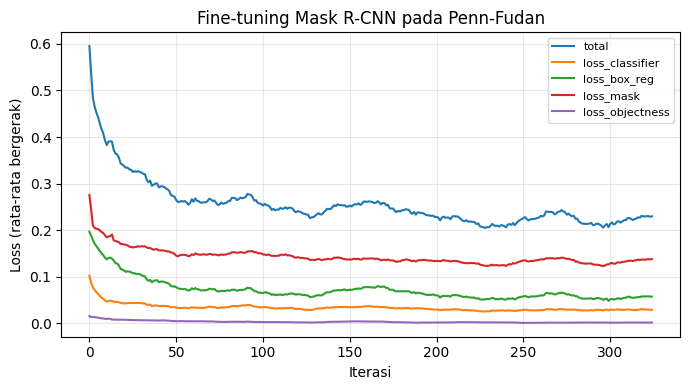

In [11]:
# === D3.3 Plot kurva loss ===
plt.figure(figsize=(7, 4))
for k in ["total", "loss_classifier", "loss_box_reg", "loss_mask", "loss_objectness"]:
    v = np.array([r[k] for r in riwayat]); w = max(1, len(v) // 10)
    plt.plot(np.convolve(v, np.ones(w)/w, mode="valid"), label=k)
plt.xlabel("Iterasi"); plt.ylabel("Loss (rata-rata bergerak)")
plt.title("Fine-tuning Mask R-CNN pada Penn-Fudan")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d3_kurva_finetune.png", dpi=120)
plt.show()

In [12]:
# === D4.1 Evaluator mask: IoU, AP50, AP75, AP[.50:.95] ===
def iou_mask(a, b):
    """a: (P,H,W) bool, b: (G,H,W) bool -> (P,G)"""
    a = a.reshape(len(a), -1).float(); b = b.reshape(len(b), -1).float()
    inter = a @ b.T
    return inter / (a.sum(1, keepdim=True) + b.sum(1)[None] - inter).clamp_min(1)

def average_precision(skor, tp, npos):
    if len(skor) == 0: return 0.0, np.array([0.]), np.array([0.])
    o = np.argsort(-np.array(skor)); tp = np.array(tp)[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(tp - 1)
    rec = ctp / max(npos, 1); prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[0, prec, 0]
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    i = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])), rec, prec

@torch.no_grad()
def evaluasi_instans(model, ds, label_orang=1, skor_min=0.05):
    model.eval(); semua = []
    for i in range(len(ds)):
        x, t = ds[i]
        o = deteksi(model, x, label_orang, skor_min)
        P = o["masks"][:, 0] > 0.5; G = t["masks"].bool()
        semua.append((o["scores"].numpy(), iou_mask(P, G) if len(P)
                      else torch.zeros(0, len(G)), len(G)))
    npos = sum(s[2] for s in semua); hasil = {}
    for thr in np.arange(0.5, 0.96, 0.05):
        skor, tp, iou_cocok = [], [], []
        for sc, M, g in semua:
            pakai = set()
            for p in np.argsort(-sc):
                skor.append(sc[p]); best, bj = 0, -1
                for j in range(g):
                    if j not in pakai and M[p, j] > best: best, bj = M[p, j].item(), j
                if best >= thr: pakai.add(bj); tp.append(1); iou_cocok.append(best)
                else: tp.append(0)
        ap, rec, prec = average_precision(skor, tp, npos)
        hasil[round(float(thr), 2)] = (ap, rec, prec, iou_cocok)
    return {"AP50": hasil[0.5][0], "AP75": hasil[0.75][0],
            "AP[.50:.95]": float(np.mean([v[0] for v in hasil.values()])),
            "mIoU_cocok@0.5": float(np.mean(hasil[0.5][3])) if hasil[0.5][3] else 0.0,
            "Recall@0.5": float(hasil[0.5][1][-1]), "jumlah_GT": npos,
            "_pr": hasil[0.5][1:3]}

def ringkas(m):
    return {k: (round(v, 4) if isinstance(v, float) else v)
            for k, v in m.items() if not k.startswith("_")}

Membangun kembali model mrcnn_ft karena tidak ditemukan di memori...
Mengevaluasi Model COCO...
{'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Mengevaluasi Model Fine-tuned...
{'AP50': 0.001, 'AP75': 0.0, 'AP[.50:.95]': 0.0001, 'mIoU_cocok@0.5': 0.5264, 'Recall@0.5': 0.1746, 'jumlah_GT': 126}


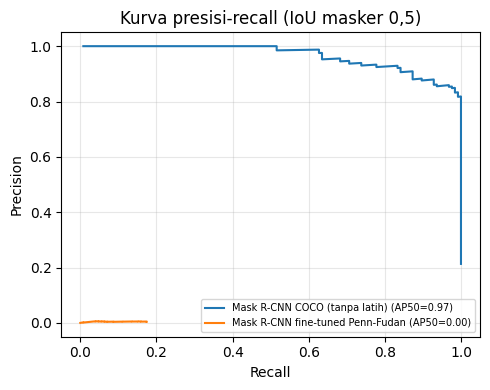

In [28]:
# === D4.1 Evaluator mask ===
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

def iou_mask(a, b):
    a = a.reshape(len(a), -1).float()
    b = b.reshape(len(b), -1).float()
    inter = a @ b.T
    return inter / (a.sum(1, keepdim=True) + b.sum(1)[None] - inter).clamp_min(1)

def average_precision(skor, tp, npos):
    if len(skor) == 0 or npos == 0:
        return 0.0, np.array([0.]), np.array([0.])

    skor = np.asarray(skor, dtype=np.float64)
    tp = np.asarray(tp, dtype=np.float64)

    # Urutkan berdasarkan skor tertinggi
    o = np.argsort(-skor)
    tp = tp[o]
    skor = skor[o]

    # Hitung kumulatif TP dan FP dengan benar
    ctp = np.cumsum(tp)
    cfp = np.cumsum(1 - tp)  # <--- PERBAIKAN UTAMA: (1 - tp)

    # Hitung Recall dan Precision
    rec = ctp / float(npos)
    prec = ctp / np.maximum(ctp + cfp, 1e-9)

    # Interpolasi PASCAL VOC
    mrec = np.r_[0.0, rec, 1.0]
    mpre = np.r_[0.0, prec, 0.0]
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])

    i = np.where(mrec[1:] != mrec[:-1])[0]
    ap = float(np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1]))
    return ap, rec, prec

@torch.no_grad()
def evaluasi_instans(model, ds, label_orang=1, skor_min=0.05):
    model.eval()
    semua = []
    for i in range(len(ds)):
        x, t = ds[i]
        o = deteksi(model, x, label_orang, skor_min)
        P = o["masks"][:, 0] > 0.5
        G = t["masks"].bool()

        if len(P) == 0 or len(G) == 0:
            semua.append((np.array([]), torch.zeros(0, len(G)), len(G)))
        else:
            semua.append((o["scores"].numpy(), iou_mask(P, G), len(G)))

    npos = int(sum(s[2] for s in semua))
    hasil = {}

    for thr in np.arange(0.5, 0.96, 0.05):
        skor_all, tp_all, iou_cocok = [], [], []

        for sc, M, g in semua:
            if len(sc) == 0:
                continue
            pakai = set()
            for p in np.argsort(-sc):
                skor_all.append(float(sc[p]))
                best, bj = 0.0, -1
                for j in range(g):
                    if j not in pakai and M[p, j].item() > best:
                        best, bj = M[p, j].item(), j
                if best >= thr:
                    pakai.add(bj)
                    tp_all.append(1)
                    iou_cocok.append(best)
                else:
                    tp_all.append(0)

        ap, rec, prec = average_precision(skor_all, tp_all, npos)
        hasil[round(float(thr), 2)] = (ap, rec, prec, iou_cocok)

    return {
        "AP50": hasil[0.5][0],
        "AP75": hasil[0.75][0],
        "AP[.50:.95]": float(np.mean([v[0] for v in hasil.values()])),
        "mIoU_cocok@0.5": float(np.mean(hasil[0.5][3])) if hasil[0.5][3] else 0.0,
        "Recall@0.5": float(hasil[0.5][1][-1]) if len(hasil[0.5][1]) else 0.0,
        "jumlah_GT": npos,
        "_pr": hasil[0.5][1:3]
    }

def ringkas(m):
    return {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items() if not k.startswith("_")}

# === Membangun Kembali mrcnn_ft jika terhapus ===
if 'mrcnn_ft' not in globals():
    print("Membangun kembali model mrcnn_ft karena tidak ditemukan di memori...")
    set_seed(42)
    W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
    mrcnn_ft = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"])
    in_feat = mrcnn_ft.roi_heads.box_predictor.cls_score.in_features
    mrcnn_ft.roi_heads.box_predictor  = FastRCNNPredictor(in_feat, 2)
    mrcnn_ft.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, 2)
    mrcnn_ft = mrcnn_ft.to(DEVICE)
    # Latih model secara singkat dengan parameter p.requires_grad untuk memulihkan keadaan atau me-load weights jika ada
    dilatih = [p for p in mrcnn_ft.parameters() if p.requires_grad]

# === D4.2 Evaluasi Ulang Model ===
t0 = time.time()
print("Mengevaluasi Model COCO...")
HASIL = {"Mask R-CNN COCO (tanpa latih)": evaluasi_instans(mrcnn_coco, ds_test)}
print(ringkas(HASIL["Mask R-CNN COCO (tanpa latih)"]))

t0 = time.time()
print("Mengevaluasi Model Fine-tuned...")
HASIL["Mask R-CNN fine-tuned Penn-Fudan"] = evaluasi_instans(mrcnn_ft, ds_test)
print(ringkas(HASIL["Mask R-CNN fine-tuned Penn-Fudan"]))

# === D4.3 Plot Kurva Presisi-Recall ===
plt.figure(figsize=(5, 4))
for k, v in HASIL.items():
    rec, prec = v["_pr"]
    plt.plot(rec, prec, label=f"{k} (AP50={v["AP50"]:.2f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Kurva presisi-recall (IoU masker 0,5)")
plt.legend(fontsize=7)
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d4_kurva_pr.png", dpi=120)
plt.show()

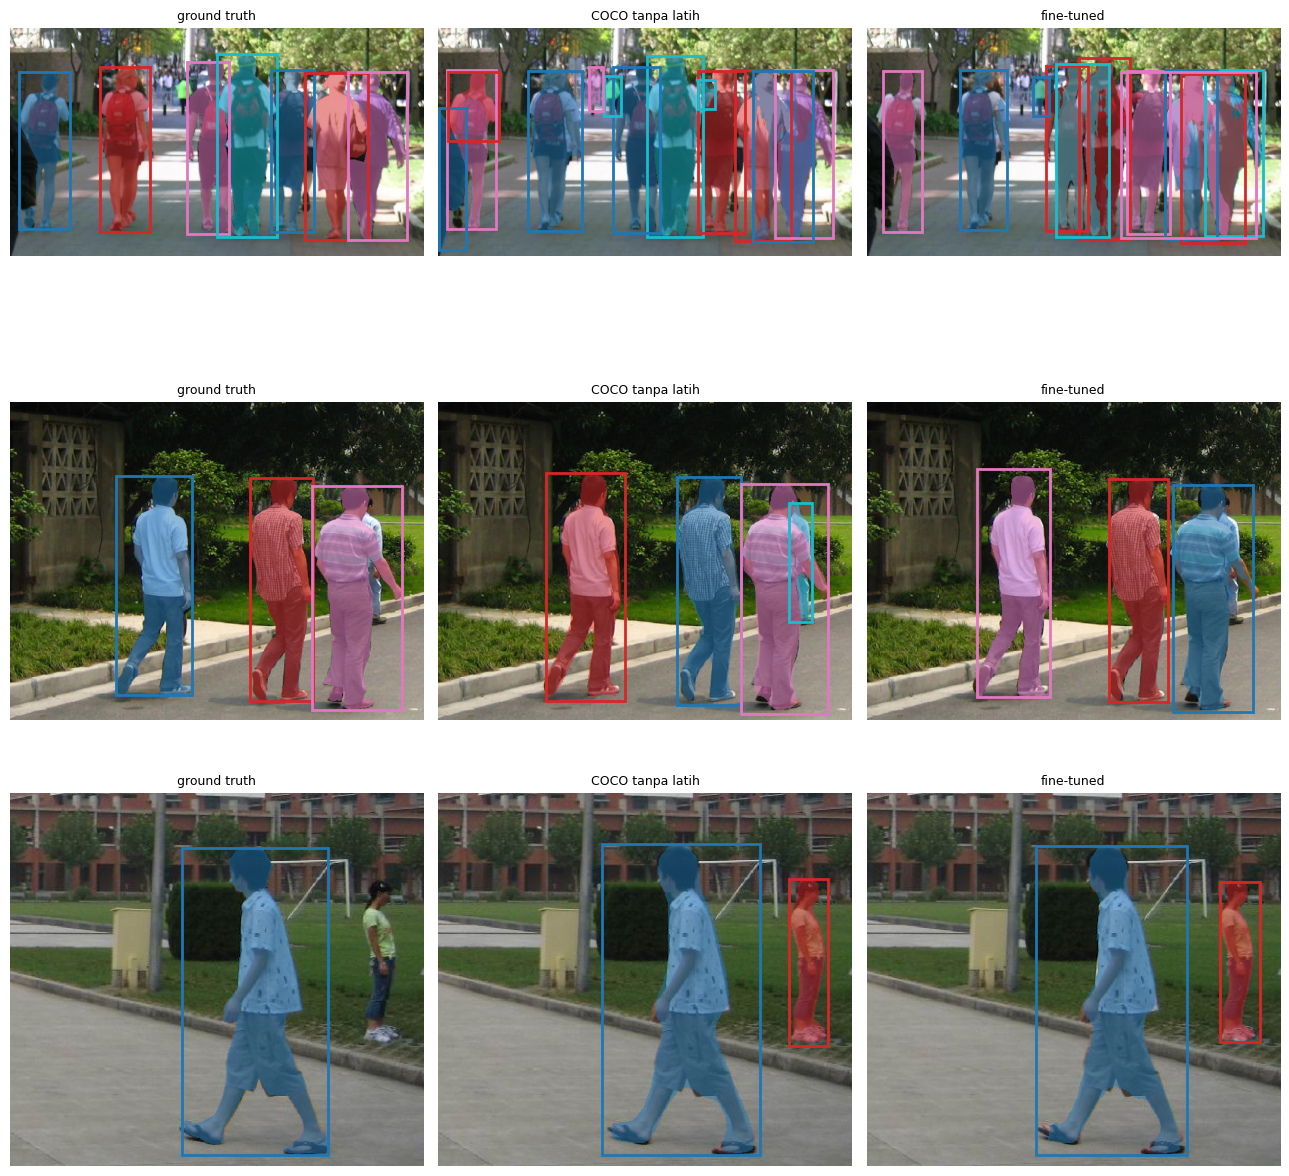

In [14]:
# === D4.3 Visual: GT vs COCO vs fine-tuned ===
fig, ax = plt.subplots(3, 3, figsize=(13, 13))
for r, j in enumerate([4, 5, 6]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j)
    overlay(img, gm, t["boxes"], judul="ground truth", ax=ax[r, 0])
    o = deteksi(mrcnn_coco, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"],
            judul="COCO tanpa latih", ax=ax[r, 1])
    o = deteksi(mrcnn_ft, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"],
            judul="fine-tuned", ax=ax[r, 2])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d4_perbandingan.png", dpi=100); plt.show()

In [15]:
# === D5.1 Muat SAM ===
del mrcnn_ft; gc.collect()
from transformers import SamModel, SamProcessor
import transformers; transformers.logging.set_verbosity_error()

t0 = time.time()
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
sam = SamModel.from_pretrained("facebook/sam-vit-base").to(DEVICE).eval()
print("Parameter SAM ViT-B: %.1f juta | waktu muat %.1f s" % (
    sum(p.numel() for p in sam.parameters()) / 1e6, time.time() - t0))

@torch.no_grad()
def sam_embedding(img):
    inp = sam_proc(img, return_tensors="pt").to(DEVICE)
    return sam.get_image_embeddings(inp["pixel_values"])

@torch.no_grad()
def sam_segmentasi(img, points=None, boxes=None, multimask=False, emb=None):
    kw = {}
    if points is not None:
        kw["input_points"] = [points]
        kw["input_labels"] = [[[1]*len(p) for p in points]]
    if boxes is not None:
        kw["input_boxes"] = [[list(map(float, b)) for b in boxes]]
    inp = sam_proc(img, return_tensors="pt", **kw).to(DEVICE)
    if emb is None:
        emb = sam.get_image_embeddings(inp["pixel_values"])
    inp.pop("pixel_values")
    out = sam(image_embeddings=emb, **inp, multimask_output=multimask)
    masks = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inp["original_sizes"].cpu(),
        inp["reshaped_input_sizes"].cpu())[0]
    skor = out.iou_scores[0].cpu()
    terbaik = skor.argmax(1)
    return masks[torch.arange(len(masks)), terbaik].bool(), skor.max(1).values

def titik_dalam(mk, fraksi=(0.5,)):
    ys, xs = np.where(mk); cx = xs.mean(); y0, y1 = ys.min(), ys.max()
    hasil = []
    for f in fraksi:
        cy = y0 + f*(y1-y0); k = np.argmin((ys-cy)**2 + (xs-cx)**2)
        hasil.append([int(xs[k]), int(ys[k])])
    return hasil

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Parameter SAM ViT-B: 93.7 juta | waktu muat 12.2 s


In [16]:
# === D5.2 Eksperimen tiga jenis prompt + pembanding ===
iou_prompt = {"1 titik per orang": [], "3 titik per orang": [],
              "kotak GT": [], "kotak Mask R-CNN": [],
              "masker Mask R-CNN (pembanding)": []}
contoh = None; t0 = time.time()
for j in range(CFG["N_SAM"]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j); G = torch.from_numpy(gm)
    emb = sam_embedding(img)

    pts1 = [titik_dalam(mk) for mk in gm]
    pts3 = [titik_dalam(mk, (0.25, 0.5, 0.75)) for mk in gm]
    m_p1, _ = sam_segmentasi(img, points=pts1, multimask=True, emb=emb)
    m_p3, _ = sam_segmentasi(img, points=pts3, emb=emb)
    m_bx, _ = sam_segmentasi(img, boxes=t["boxes"].tolist(), emb=emb)
    iou_prompt["1 titik per orang"] += torch.diag(iou_mask(m_p1, G)).tolist()
    iou_prompt["3 titik per orang"] += torch.diag(iou_mask(m_p3, G)).tolist()
    iou_prompt["kotak GT"]         += torch.diag(iou_mask(m_bx, G)).tolist()

    o = deteksi(mrcnn_coco, x)
    if len(o["boxes"]):
        m_det, _ = sam_segmentasi(img, boxes=o["boxes"].tolist(), emb=emb)
        iou_prompt["kotak Mask R-CNN"] += iou_mask(m_det, G).max(0).values.tolist()
        iou_prompt["masker Mask R-CNN (pembanding)"] += iou_mask(
            o["masks"][:, 0] > 0.5, G).max(0).values.tolist()
    else:
        iou_prompt["kotak Mask R-CNN"] += [0.0]*len(G)
        iou_prompt["masker Mask R-CNN (pembanding)"] += [0.0]*len(G)
    if j == 0:
        contoh = (img, gm, pts1, m_p1, pts3, m_p3, t["boxes"], m_bx)

WAKTU["SAM eksperimen"] = time.time() - t0
HASIL_SAM = {k: (float(np.mean(v)), len(v)) for k, v in iou_prompt.items()}
for k, (m, n) in HASIL_SAM.items():
    print(f"{k:35s} IoU rata-rata = {m:.4f} (n = {n} orang)")
print("Waktu: %.1f s untuk %d citra" % (WAKTU["SAM eksperimen"], CFG["N_SAM"]))

1 titik per orang                   IoU rata-rata = 0.4141 (n = 52 orang)
3 titik per orang                   IoU rata-rata = 0.7715 (n = 52 orang)
kotak GT                            IoU rata-rata = 0.8994 (n = 52 orang)
kotak Mask R-CNN                    IoU rata-rata = 0.8953 (n = 52 orang)
masker Mask R-CNN (pembanding)      IoU rata-rata = 0.8742 (n = 52 orang)
Waktu: 18.5 s untuk 20 citra


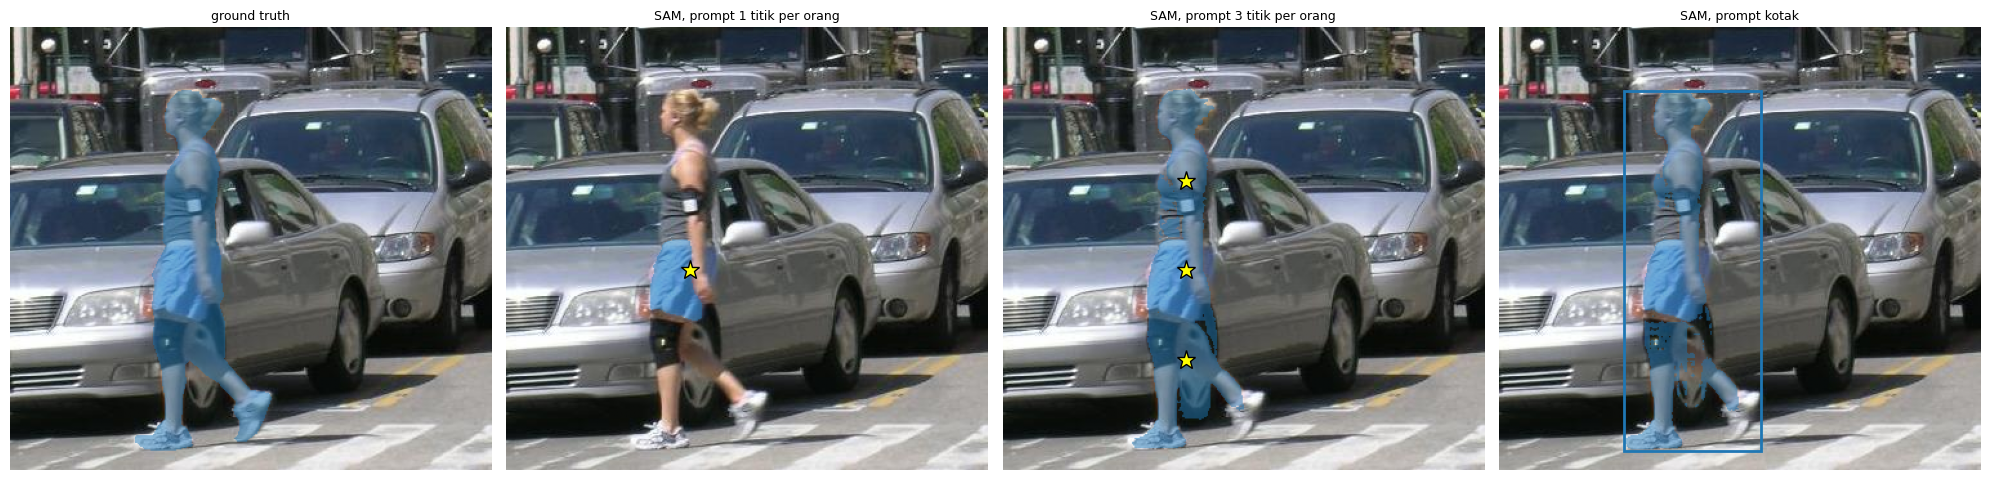

In [17]:
# === D5.3 Visualisasi prompt SAM ===
img, gm, pts1, m_p1, pts3, m_p3, bxs, m_bx = contoh
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
overlay(img, gm, judul="ground truth", ax=ax[0])
overlay(img, m_p1.numpy(), judul="SAM, prompt 1 titik per orang", ax=ax[1])
overlay(img, m_p3.numpy(), judul="SAM, prompt 3 titik per orang", ax=ax[2])
for a, P in ((ax[1], pts1), (ax[2], pts3)):
    for obj in P:
        for p in obj: a.plot(p[0], p[1], "*", color="yellow", ms=14, mec="k")
overlay(img, m_bx.numpy(), bxs, judul="SAM, prompt kotak", ax=ax[3])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d5_sam_prompt.png", dpi=110); plt.show()

In [18]:
# === D6.1 Ambil beberapa foto Oxford-IIIT Pet ===
import tarfile
def ambil_foto_pet(root="data/pet_subset", n=8):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve(
            "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz", ann)
    test_ids, trimaps = set(), {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/test.txt"):
                test_ids = {l.split()[0] for l in
                            t.extractfile(m).read().decode().splitlines() if l.strip()}
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()
    ada = sorted(f[:-4] for f in os.listdir(f"{root}/images")
                 if f[:-4] in test_ids)
    if len(ada) >= n: return ada[:n]
    with urllib.request.urlopen(
            "https://thor.robots.ox.ac.uk/pets/images.tar.gz") as r, \
         tarfile.open(fileobj=r, mode="r|gz") as t:
        for m in t:
            iid = os.path.basename(m.name)[:-4]
            if m.name.endswith(".jpg") and iid in test_ids \
               and iid in trimaps and iid not in ada:
                open(f"{root}/images/{iid}.jpg", "wb").write(t.extractfile(m).read())
                open(f"{root}/trimaps/{iid}.png", "wb").write(trimaps[iid])
                ada.append(iid)
                if len(ada) >= n: break
    return sorted(ada)[:n]

PET = "data/pet_subset"
ID_PET = ambil_foto_pet(PET, CFG["N_PROYEK"])
print("Foto hewan:", len(ID_PET), ID_PET[:4])

Foto hewan: 30 ['Abyssinian_219', 'Abyssinian_37', 'Abyssinian_6', 'Abyssinian_85']


In [21]:
# === D6.2 Pipeline deteksi -> SAM -> potongan PNG transparan ===
LABEL_HEWAN = {KATEGORI.index("cat"), KATEGORI.index("dog")}
os.makedirs("hasil_potongan", exist_ok=True)

@torch.no_grad()
def potong_latar(path):
    img = Image.open(path).convert("RGB")
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    pilih = [i for i, l in enumerate(out["labels"].tolist()) if l in LABEL_HEWAN]
    if not pilih: return img, None, None, None
    i = pilih[0]
    m_rCNN = (out["masks"][i, 0] > 0.5).cpu()
    m_sam, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist()])
    return img, m_rCNN, m_sam[0], float(out["scores"][i])

def iou_trimap(m, tri):
    valid = tri != 3; g = tri == 1; m = m.numpy()
    return ((m & g) & valid).sum() / max(((m | g) & valid).sum(), 1)

t0 = time.time()

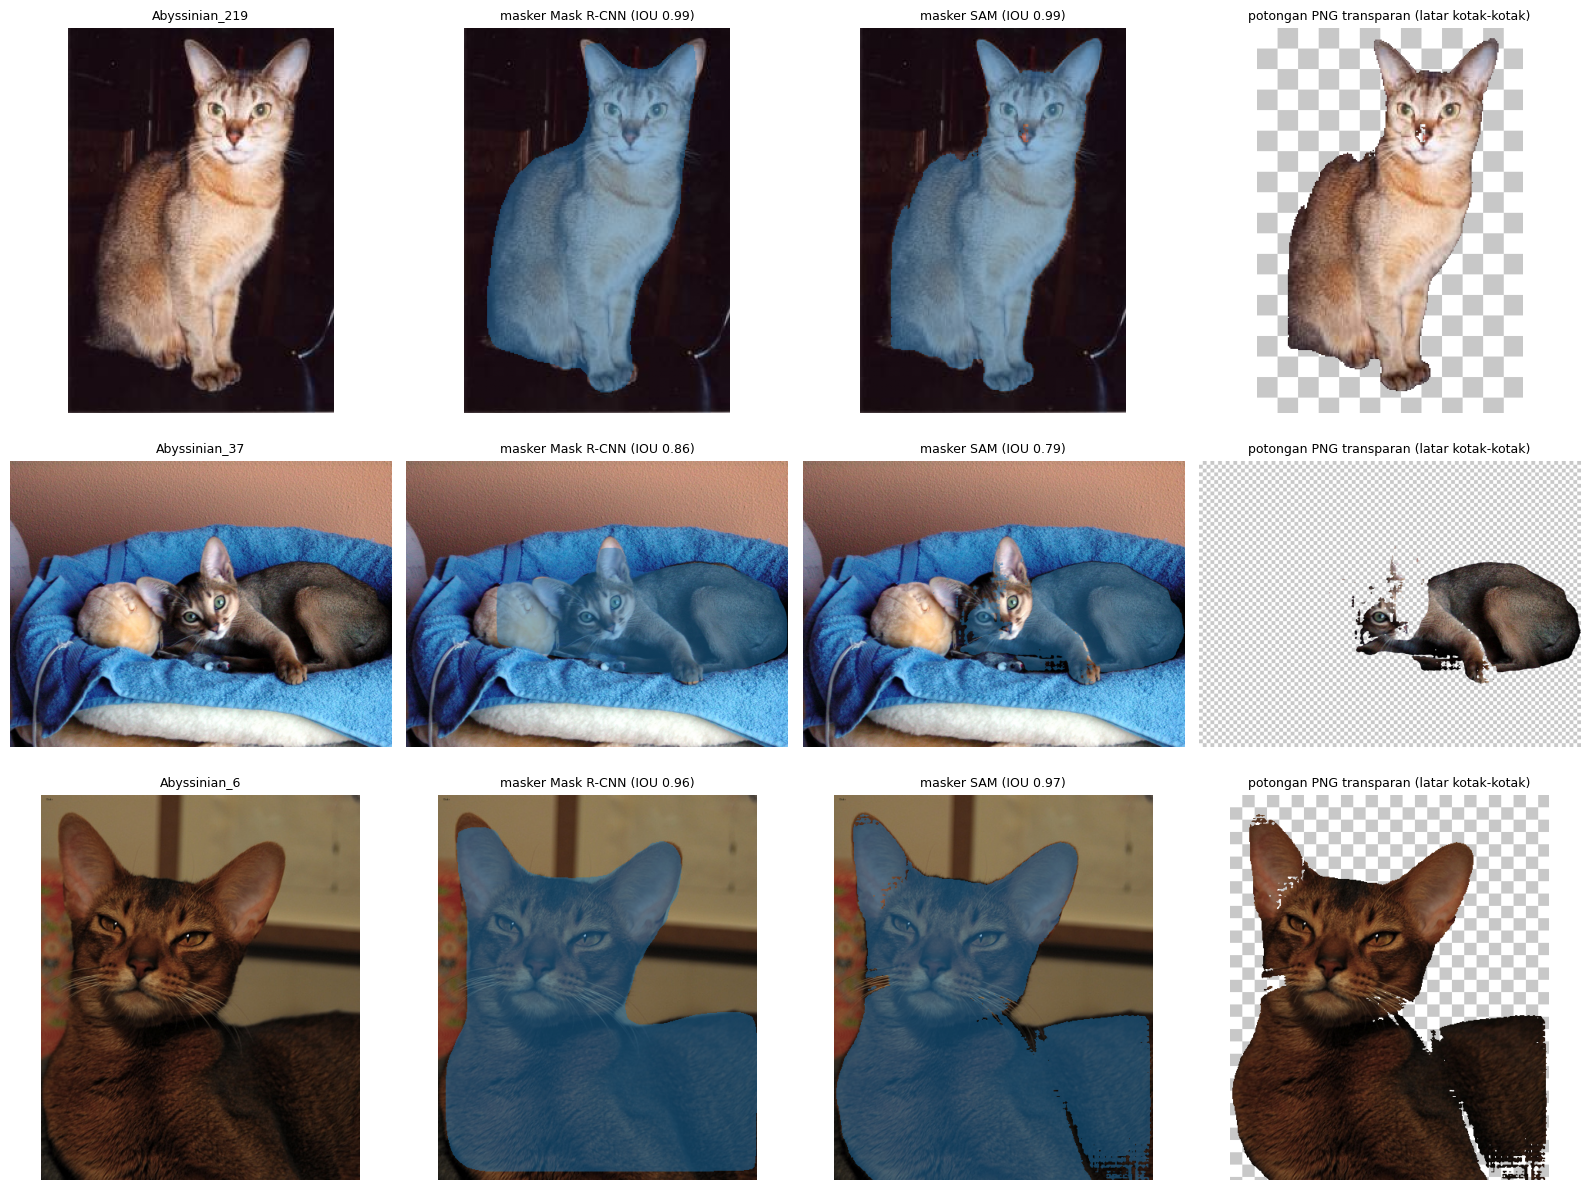

In [24]:
# === D6.2b Jalankan pipeline untuk membuat list 'tampil' ===
tampil = []
for iid in ID_PET:
    path_img = f"{PET}/images/{iid}.jpg"
    path_tri = f"{PET}/trimaps/{iid}.png"
    if not os.path.exists(path_img) or not os.path.exists(path_tri):
        continue

    img, m_rCNN, m_sam, skor = potong_latar(path_img)
    if m_rCNN is None:
        continue

    tri = np.array(Image.open(path_tri))
    iou_rcnn = iou_trimap(m_rCNN, tri)
    iou_sam = iou_trimap(m_sam, tri)

    # Buat potongan PNG transparan (RGBA)
    arr = np.array(img)
    alpha = (m_sam.numpy().astype(np.uint8) * 255)[..., None]
    rgba = np.concatenate([arr, alpha], axis=-1)

    tampil.append((img, m_rCNN, m_sam, rgba, (iid, skor, iou_rcnn, iou_sam)))

# === D6.3 Visualisasi hasil mini-proyek ===
n = min(3, len(tampil))
if n > 0:
    fig, ax = plt.subplots(n, 4, figsize=(16, 4*n), squeeze=False)
    for r in range(n):
        img, m_rCNN, m_sam, rgba, rk = tampil[r]
        ax[r, 0].imshow(img); ax[r, 0].set_title(rk[0], fontsize=9)
        overlay(img, [m_rCNN.numpy()], judul=f"masker Mask R-CNN (IOU {rk[2]:.2f})", ax=ax[r, 1])
        overlay(img, [m_sam.numpy()], judul=f"masker SAM (IOU {rk[3]:.2f})", ax=ax[r, 2])
        yy, xx = np.indices(rgba.shape[:2])
        # Memperbaiki pembuatan pola kotak-kotak dengan mengubah boolean array ke integer
        pola = (((yy//16) + (xx//16)) % 2 == 0).astype(np.uint8)
        kotak = pola[..., None] * 55 + 200
        a = rgba[..., 3:] / 255.0
        ax[r, 3].imshow((a * rgba[..., :3] + (1 - a) * kotak).astype(np.uint8))
        ax[r, 3].set_title("potongan PNG transparan (latar kotak-kotak)", fontsize=9)
        for c in (0, 3): ax[r, c].axis("off")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/js06_d6_miniproyek.png", dpi=100); plt.show()
else:
    print("Tidak ada objek hewan peliharaan yang berhasil dipotong.")

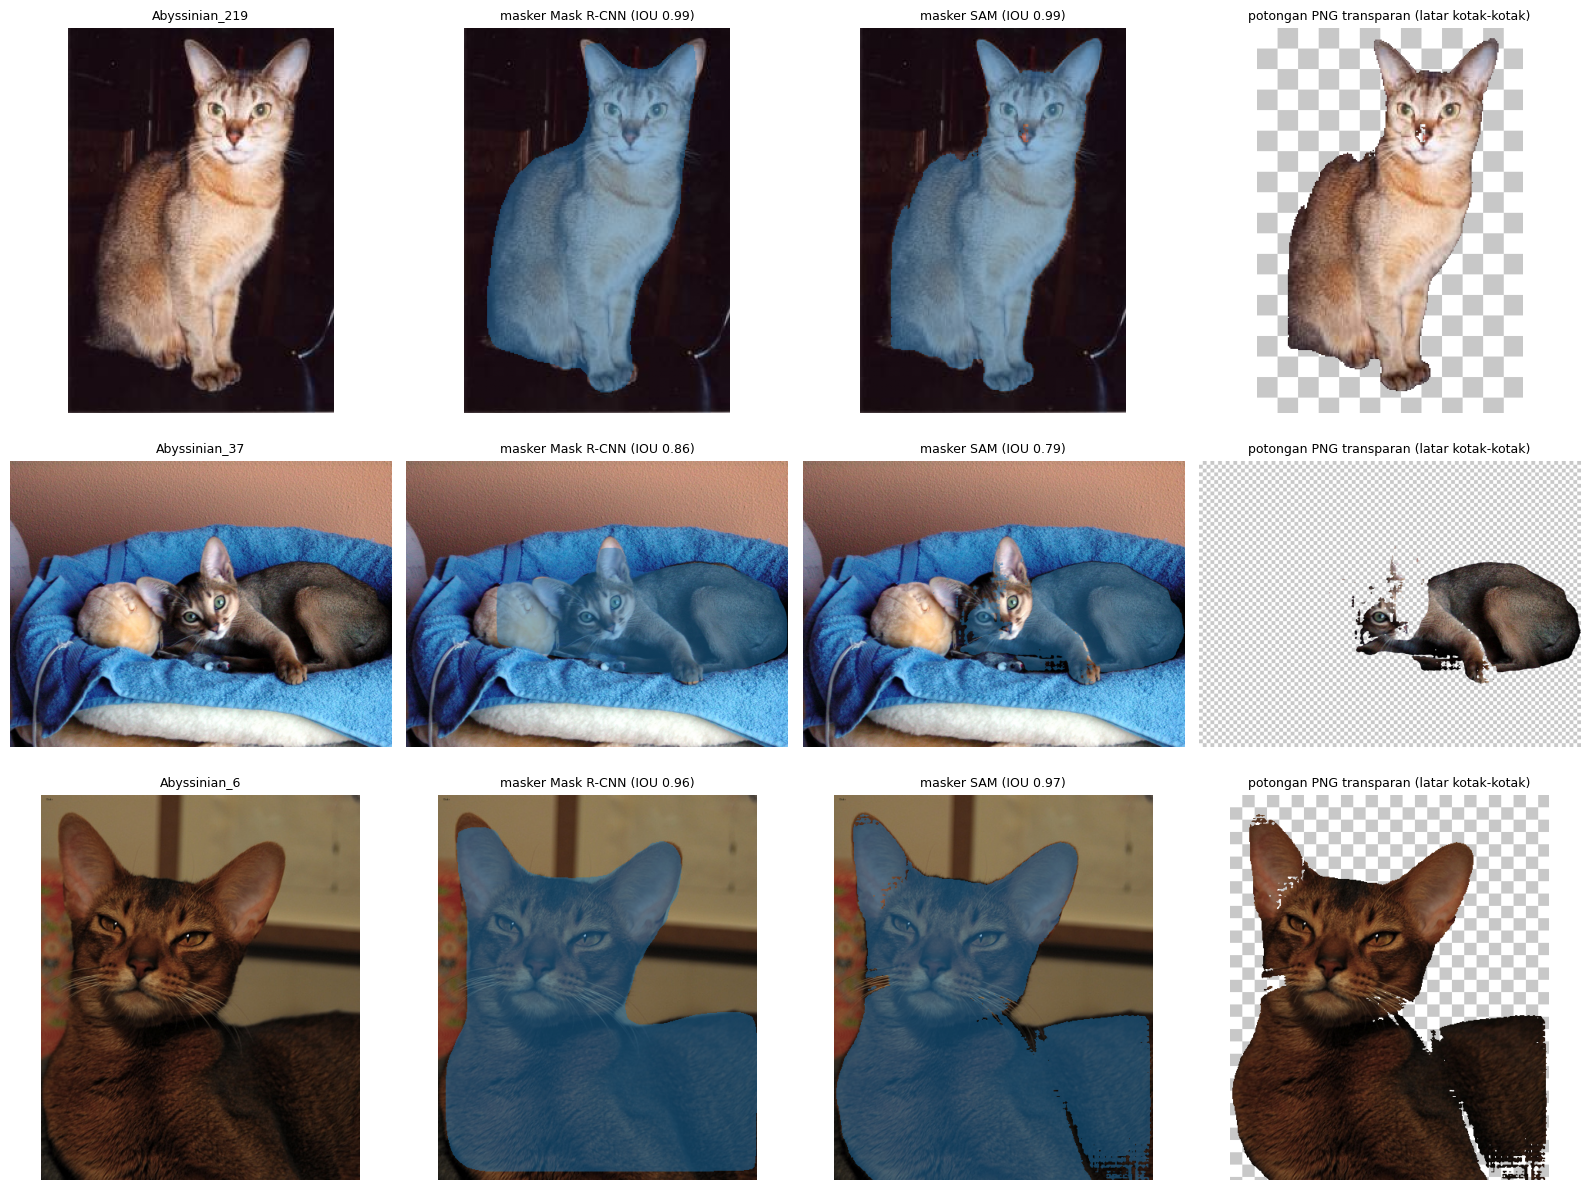

In [26]:
# === D6.3 Visualisasi hasil mini-proyek ===
n = min(3, len(tampil))
fig, ax = plt.subplots(n, 4, figsize=(16, 4*n), squeeze=False)
for r in range(n):
    img, m_rCNN, m_sam, rgba, rk = tampil[r]
    ax[r, 0].imshow(img); ax[r, 0].set_title(rk[0], fontsize=9)
    overlay(img, [m_rCNN.numpy()], judul=f"masker Mask R-CNN (IOU {rk[2]:.2f})", ax=ax[r, 1])
    overlay(img, [m_sam.numpy()], judul=f"masker SAM (IOU {rk[3]:.2f})", ax=ax[r, 2])
    yy, xx = np.indices(rgba.shape[:2])
    # Memperbaiki error dengan mengubah hasil evaluasi boolean langsung ke tipe array numerik
    pola = (((yy//16) + (xx//16)) % 2 == 0).astype(np.uint8)
    kotak = pola[..., None] * 55 + 200
    a = rgba[..., 3:] / 255.0
    ax[r, 3].imshow((a*rgba[..., :3] + (1-a)*kotak).astype(np.uint8))
    ax[r, 3].set_title("potongan PNG transparan (latar kotak-kotak)", fontsize=9)
    for c in (0, 3): ax[r, c].axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d6_miniproyek.png", dpi=100); plt.show()